# PIM VI — Experimentos com agenda e fila
Clínica Horizonte é um cenário sintético. Os resultados medem capacidade de recuperar padrões da simulação. Os modelos não controlam a fila.
1. Falta, prevista na marcação. 2. Espera, estimada no check-in para quem chegou. 3. Lotação, classificada na abertura do bloco.
Execute em ordem a partir desta pasta. A saída é salva em `resultados/`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier, GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, mean_absolute_error, root_mean_squared_error)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from simular import gerar

out = Path('resultados')
out.mkdir(exist_ok=True)
fonte = Path('atendimentos.csv')
gerar(fonte)
bruto = pd.read_csv(fonte, parse_dates=['bloco_inicio'])
assert bruto['no_show'].isin([0, 1]).all() and bruto['lotacao'].isin([0, 1]).all()
assert bruto.loc[bruto['no_show'].eq(1), 'espera_min'].isna().all()
assert bruto.loc[bruto['no_show'].eq(0), ['espera_min','fila_chegada']].ge(0).all().all()
# Registros idênticos podem representar marcações diferentes. Usa-se a granularidade declarada.
dados = bruto.sort_values('bloco_inicio', kind='stable').reset_index(drop=True)
dias = dados['bloco_inicio'].dt.normalize().drop_duplicates().tolist()
corte = dias[int(len(dias) * .8)]
treino_eda = dados[dados['bloco_inicio'] < corte]
print(f'{len(dados)} marcações; {len(dias)} dias úteis; teste desde {corte.date()}.')
print(dados.isna().sum().to_string())

3410 marcações; 135 dias úteis; teste desde 2026-06-04.
bloco_inicio           0
tipo                   0
turno                  0
dia_semana             0
antecedencia_dias      0
faltas_previas       192
fila_chegada         776
marcacoes_bloco        0
pendentes_inicio       0
capacidade_bloco       0
no_show                0
espera_min           776
lotacao                0


## Análise exploratória
Exploração apenas no treino. Ausência de espera nos casos de falta é estrutural, então não se imputa o alvo. A análise de lotação usa uma linha por bloco. Correlações descritivas não são evidência causal.

{
  "marcacoes": 3410,
  "treino": 2670,
  "teste": 740,
  "blocos": 540,
  "corte": "2026-06-04",
  "faltas_treino_pct": 23.1,
  "lotacao_treino_pct": 26.9,
  "espera_treino_media": 12.6,
  "espera_treino_mediana": 9.0,
  "espera_treino_p90": 32.4,
  "faltas_previas_ausentes": 192,
  "corr_fila_espera": 0.83
}


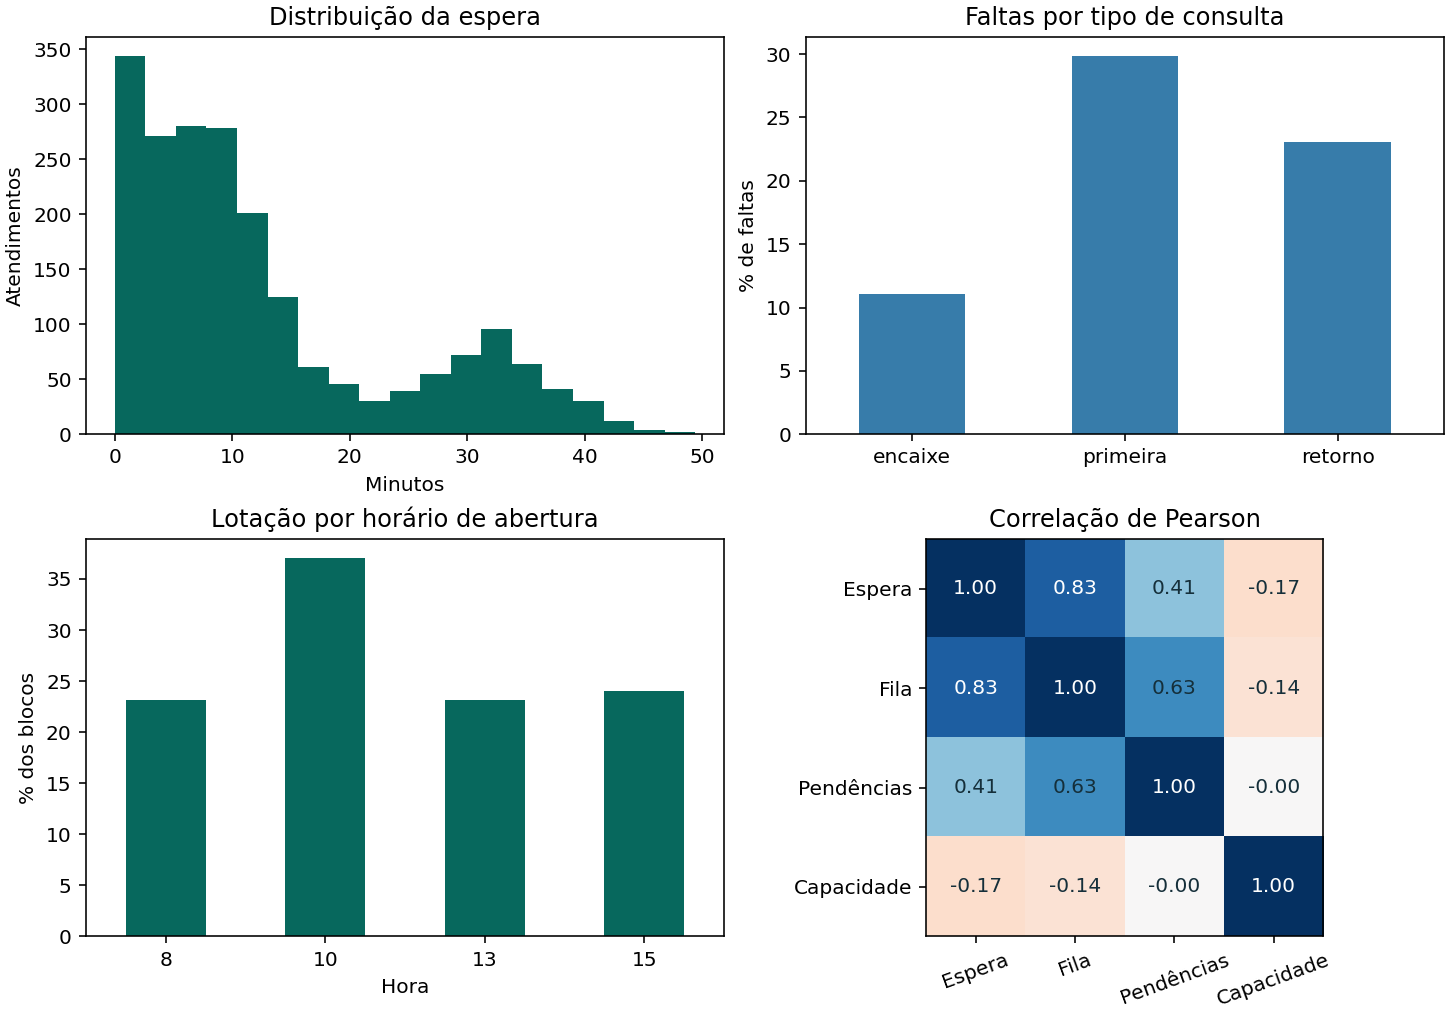

In [2]:
blocos_eda = treino_eda.drop_duplicates('bloco_inicio')
fig, ax = plt.subplots(2, 2, figsize=(10, 7), layout='constrained')
fig.patch.set_facecolor('#ffffff')
ax[0,0].hist(treino_eda['espera_min'].dropna(), bins=19, color='#07685d')
ax[0,0].set(title='Distribuição da espera', xlabel='Minutos', ylabel='Atendimentos')
treino_eda.groupby('tipo')['no_show'].mean().mul(100).plot.bar(ax=ax[0,1], color='#377caa', rot=0)
ax[0,1].set(title='Faltas por tipo de consulta', xlabel='', ylabel='% de faltas')
blocos_eda.groupby(blocos_eda['bloco_inicio'].dt.hour)['lotacao'].mean().mul(100).plot.bar(ax=ax[1,0], color='#07685d', rot=0)
ax[1,0].set(title='Lotação por horário de abertura', xlabel='Hora', ylabel='% dos blocos')
corr = treino_eda[['espera_min', 'fila_chegada','pendentes_inicio','capacidade_bloco']].corr()
imagem = ax[1,1].imshow(corr, vmin=-1, vmax=1, cmap='RdBu')
nomes = ['Espera','Fila','Pendências','Capacidade']
ax[1,1].set(xticks=range(4), yticks=range(4), xticklabels=nomes, yticklabels=nomes, title='Correlação de Pearson')
ax[1,1].tick_params(axis='x', labelrotation=20)
for i in range(4):
    for j in range(4):
        val = corr.iloc[i,j]
        ax[1,1].text(j, i, f'{val:.2f}', ha='center', va='center', color='white' if abs(val) > .70 else '#152f3a')
fig.savefig(out / 'exploratoria.png', dpi=145)
plt.close(fig)
display(Image(filename=str(out / 'exploratoria.png')))
estat = {'marcacoes':len(dados), 'treino':len(treino_eda), 'teste':len(dados)-len(treino_eda),
         'blocos':int(dados['bloco_inicio'].nunique()), 'corte': str(corte.date()),
         'faltas_treino_pct': round(treino_eda['no_show'].mean()*100,1),
         'lotacao_treino_pct':round(blocos_eda['lotacao'].mean()*100,1),
         'espera_treino_media':round(treino_eda['espera_min'].mean(),1),
         'espera_treino_mediana':round(treino_eda['espera_min'].median(),1),
         'espera_treino_p90':round(treino_eda['espera_min'].quantile(.9),1),
         'faltas_previas_ausentes':int(dados['faltas_previas'].isna().sum()),
         'corr_fila_espera':round(corr.loc['espera_min','fila_chegada'],2)}
print(json.dumps(estat, ensure_ascii=False, indent=2))

## Pré-processamento e comparação
Mediana e padronização para numéricos, moda e one-hot para categorias. O pipeline ajusta essas transformações dentro de cada dobra. A separação usa dias inteiros e deixa um dia de intervalo em cada dobra temporal. A seleção usa AUC ou RMSE na validação, antes da leitura das métricas de teste. O classificador dummy serve de referência para desbalanceamento. O limiar de classificação é 0,5.

In [3]:
ausencia = (dados, ['tipo','turno','dia_semana'], ['antecedencia_dias','faltas_previas'])
espera = (dados.dropna(subset=['espera_min']), ['tipo','turno'], ['fila_chegada','pendentes_inicio','capacidade_bloco'])
lotacao = (dados.drop_duplicates('bloco_inicio'), ['turno','dia_semana'], ['marcacoes_bloco','pendentes_inicio','capacidade_bloco'])
tarefas = {'no_show':ausencia, 'espera_min':espera, 'lotacao':lotacao}
todos, escolhas, previsoes = [], [], []

def pipeline(cat, num, modelo):
    preprocessar = ColumnTransformer([
        ('num', Pipeline([('imputar',SimpleImputer(strategy='median')), ('padronizar',StandardScaler())]), num),
        ('cat', Pipeline([('imputar',SimpleImputer(strategy='most_frequent')),
                           ('codificar',OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat)
    ])
    return Pipeline([('dados',preprocessar),('modelo',modelo)])

def dobras_temporais(datas):
    unicos = datas.drop_duplicates().to_numpy()
    return [(np.flatnonzero(datas.isin(unicos[a])), np.flatnonzero(datas.isin(unicos[b])))
            for a, b in TimeSeriesSplit(4,gap=1).split(unicos)]

def avaliar(y, pred, prob=None):
    if prob is None:
        return {'MAE':mean_absolute_error(y,pred), 'RMSE':root_mean_squared_error(y,pred)}
    return {'acuracia':accuracy_score(y,pred), 'precisao':precision_score(y,pred,zero_division=0),
            'recall':recall_score(y,pred,zero_division=0), 'F1':f1_score(y,pred,zero_division=0),
            'AUC':roc_auc_score(y,prob)}

for alvo, (base, cat, num) in tarefas.items():
    regressao = alvo == 'espera_min'
    treino = base[base['bloco_inicio'] < corte]
    teste = base[base['bloco_inicio'] >= corte]
    x, y = treino[cat+num], treino[alvo]
    xt, yt = teste[cat+num], teste[alvo]
    cv = dobras_temporais(treino['bloco_inicio'].dt.normalize())
    if regressao:
        modelos = {'Dummy mediana':DummyRegressor(strategy='median'),
                   'Regressão linear':LinearRegression(),
                   'Gradient Boosting':GradientBoostingRegressor(random_state=42)}
        flexivel, grade = 'Gradient Boosting', {'modelo__max_depth':[2,3,4], 'modelo__n_estimators':[60,110]}
        score = 'neg_root_mean_squared_error'
    else:
        modelos = {'Dummy prevalência':DummyClassifier(strategy='prior'),
                   'Regressão logística':LogisticRegression(max_iter=1000),
                   'Random Forest':RandomForestClassifier(n_estimators=100,random_state=42,min_samples_leaf=5)}
        flexivel, grade = 'Random Forest', {'modelo__max_depth':[3,6,10], 'modelo__min_samples_leaf':[3,8]}
        score = 'roc_auc'
    ajustados = {}
    for nome, modelo in modelos.items():
        proc = pipeline(cat,num,modelo)
        validacao = cross_val_score(proc,x,y,cv=cv,scoring=score,error_score='raise').mean()
        ajustados[nome] = (validacao, proc.fit(x,y))
    grid = GridSearchCV(pipeline(cat,num,modelos[flexivel]), grade, cv=cv, scoring=score,error_score='raise')
    grid.fit(x,y)
    ajustados[flexivel + ' ajustado'] = (grid.best_score_, grid.best_estimator_)
    candidatos = {nome: par for nome,par in ajustados.items() if not nome.startswith('Dummy')}
    melhor = max(candidatos,key=lambda nome:candidatos[nome][0])
    escolhas.append({'alvo':alvo,'selecionado':melhor,'grade_melhor':grid.best_params_,'treino':len(treino),'teste':len(teste)})
    for nome,(cv_score,estimador) in ajustados.items():
        pred = estimador.predict(xt)
        prob = None if regressao else estimador.predict_proba(xt)[:,1]
        metricas = avaliar(yt,pred,prob)
        todos.append({'alvo':alvo,'modelo':nome,'CV_RMSE' if regressao else 'CV_AUC':
                      -cv_score if regressao else cv_score,**metricas})
        if nome == melhor:
            previsoes.extend({'alvo':alvo,'bloco_inicio':bloco,'observado':obs,'previsto':round(float(estim),4)}
                for bloco,obs,estim in zip(teste['bloco_inicio'],yt,pred if regressao else prob))

## Resultados e salvamento
Compare os modelos de referência, os modelos originais e a configuração ajustada. O CSV de previsões registra a probabilidade de classe positiva nos dois classificadores e minutos na regressão. A maioria das decisões depende do custo dos erros e de validação com dados reais autorizados.

In [4]:
tabela = pd.DataFrame(todos).round(4)
tabela.to_csv(out / 'metricas.csv', index=False)
pd.DataFrame(previsoes).to_csv(out / 'previsoes_teste.csv', index=False)
(out / 'resumo.json').write_text(json.dumps({'estatisticas':estat,'selecao':escolhas},
                                   ensure_ascii=False,indent=2), encoding='utf-8')
print(tabela.to_string(index=False))
print(json.dumps(escolhas, ensure_ascii=False, indent=2))
assert len(escolhas) == 3 and len(tabela) == 12

      alvo                     modelo  CV_AUC  acuracia  precisao  recall     F1    AUC  CV_RMSE    MAE    RMSE
   no_show          Dummy prevalência  0.5000    0.7865    0.0000  0.0000 0.0000 0.5000      NaN    NaN     NaN
   no_show        Regressão logística  0.7016    0.8054    0.6667  0.1772 0.2800 0.7196      NaN    NaN     NaN
   no_show              Random Forest  0.6550    0.7824    0.4762  0.1899 0.2715 0.6791      NaN    NaN     NaN
   no_show     Random Forest ajustado  0.6958    0.7919    1.0000  0.0253 0.0494 0.7061      NaN    NaN     NaN
espera_min              Dummy mediana     NaN       NaN       NaN     NaN    NaN    NaN  11.6942 9.6962 13.5109
espera_min           Regressão linear     NaN       NaN       NaN     NaN    NaN    NaN   6.2051 5.0949  6.5973
espera_min          Gradient Boosting     NaN       NaN       NaN     NaN    NaN    NaN   5.2328 4.3076  5.5383
espera_min Gradient Boosting ajustado     NaN       NaN       NaN     NaN    NaN    NaN   5.1700 4.3227 